In [27]:
import numpy as np
import matplotlib.pyplot as plt

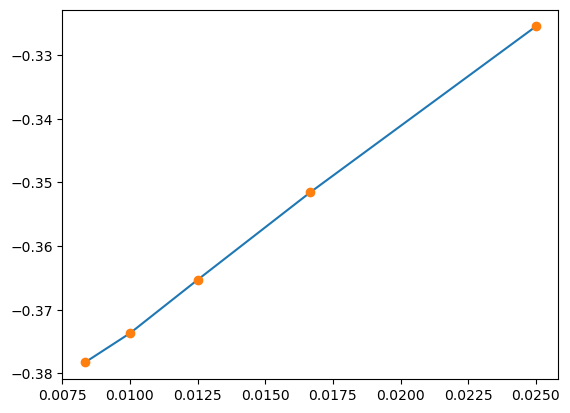

In [50]:
import json
from pathlib import Path

runs = sorted(Path("../runs/e0-fit/tau240").glob("n*/results/merged.json"),
              key=lambda p: int(p.parts[-3][1:]))
n = np.array([int(p.parts[-3][1:]) for p in runs])
E = np.array([json.load(open(p))["e0_thermo"]["mean"] for p in runs])
u = 1 / n

plt.plot(u, E)
plt.plot(u, E, "o")
plt.show()

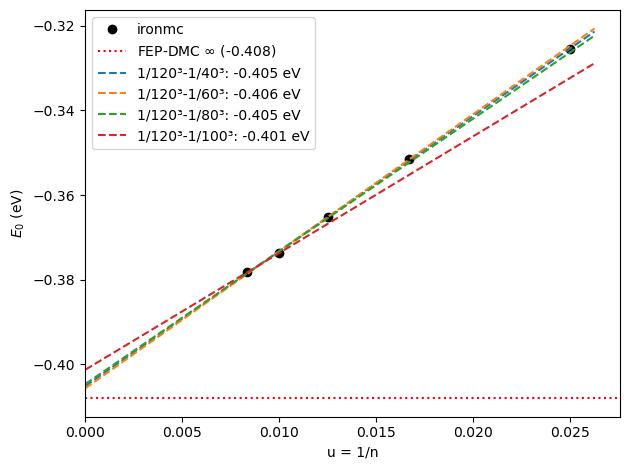

In [49]:
us = np.linspace(0, u.max() * 1.05, 100)
plt.plot(u, E, "ko", label="ironmc")
plt.axhline(-0.408, color="r", ls=":", label="FEP-DMC $\\infty$ (-0.408)")

for k in range(len(u)-1):
    m=slice(k,None)
    c1, c0 = np.polyfit(u[m], E[m], 1)
    plt.plot(us, c0 + c1 * us,  "--", label=f"1/{int(1/u[m][-1])}³-1/{int(1/u[m][0])}³: {c0:.3f} eV")

plt.xlabel("u = 1/n"); plt.ylabel(r"$E_0$ (eV)"); plt.xlim(left=0)
plt.legend(); plt.tight_layout(); plt.savefig("ladder.png", dpi=150); plt.show()

$$E_0(u) = E_\infty + C u + D u^2 + \dots$$